## Step 1: Import Required Libraries

In this step, I import the libraries required for data analysis, data visualization,
data preprocessing, machine learning model building, and model evaluation.

Pandas and NumPy are used for data manipulation and numerical operations.
Matplotlib and Seaborn are used for visualization.
Scikit-learn provides preprocessing methods, machine learning algorithms,
and evaluation metrics.

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\GEETHIKA\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [4]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\GEETHIKA\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("Libraries imported successfully.")

Libraries imported successfully.


**Code explanation**

pandas → handles tables and datasets.

numpy → performs numerical operations.

matplotlib → creates graphs.

seaborn → creates statistical visualizations.

train_test_split → divides data into training and testing sets.

ColumnTransformer → applies different preprocessing to different column types.

Pipeline → combines preprocessing and model steps.

SimpleImputer → handles missing values.

OneHotEncoder → converts categorical values into numbers.

StandardScaler → scales numerical features.

The five regressors are the models we will compare.

The three metrics evaluate regression performance.

## Step 2: Load the Dataset

In this step, I load the `train.csv` file into a Pandas DataFrame.

The dataset contains information about houses and their corresponding sale prices.
Loading the dataset is the first step before performing analysis and preprocessing.

In [6]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


## Step 3: Check Dataset Shape

I check the number of rows and columns to understand the size of the dataset.
Rows represent individual houses and columns represent their characteristics
and the target variable.

In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1460
Number of columns: 81


## Step 4: Display the First Five Rows

I display the first five records to understand the structure and values
present in the dataset.

In [8]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**Explanation**

head() displays the first five rows.

This gives an initial idea about:

feature names

data values

numerical features

categorical features

## Step 5: Dataset Information

I use the `info()` function to inspect the column names, data types,
and number of non-null values.

This helps identify numerical and categorical variables and possible
missing values.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

**Explanation**

info() tells us:

column names

data type

number of non-null values

total number of entries

## Step 6: Statistical Summary

I use descriptive statistics to understand the numerical features.

This helps identify their minimum, maximum, average, and distribution.

In [10]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


**Explanation**

describe() provides:

count

mean

standard deviation

minimum

25th percentile

median

75th percentile

maximum

## Step 7: Duplicate Analysis

I check whether the dataset contains duplicate rows.

Duplicate observations can give some records unnecessary importance during
model training, so they should be identified before modeling.

In [11]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


**Explanation**

duplicated() identifies repeated rows.

If the result is:

0

there are no exact duplicate rows to remove.

## Step 8: Missing Value Analysis

I calculate the number of missing values in every column.

Missing values must be handled appropriately because machine-learning
algorithms generally require complete numerical input.

In [12]:
missing = df.isnull().sum()

missing = missing[missing > 0]

missing.sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

**Explanation**
isnull() identifies missing values.

sum() counts them.

Columns with zero missing values are removed from the displayed result.

Sorting helps identify columns with the largest number of missing values.

## Step 9: Analyze the Target Variable

`SalePrice` is the target variable that we want to predict.

I examine its statistical summary and distribution to understand the
range and shape of house prices.

SalePrice statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

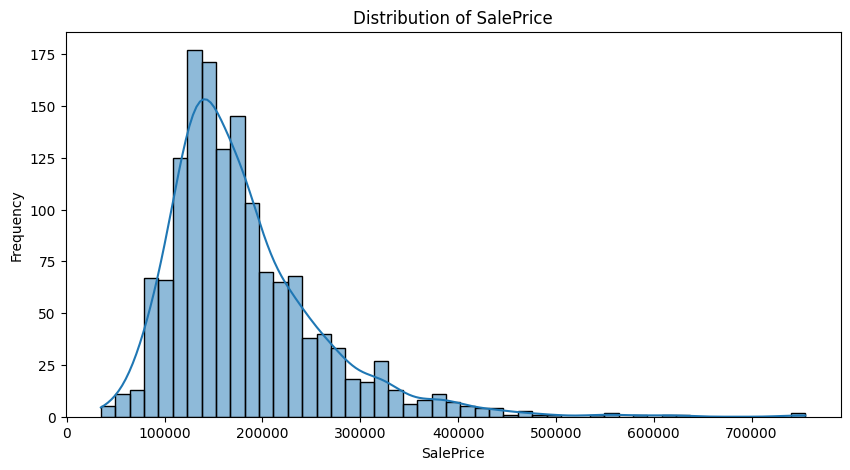

In [13]:
print("SalePrice statistics:")
display(df["SalePrice"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["SalePrice"], kde=True)

plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")

plt.show()

**Explanation**

The histogram shows how frequently different house prices occur

## Step 10: Identify Feature Types

I separate the numerical and categorical features.

This is necessary because numerical and categorical data require different
preprocessing techniques.

In [14]:
numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include="object").columns

print("Number of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns.tolist())

Number of numerical columns: 38
Number of categorical columns: 43

Categorical columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


**Explanation**

select_dtypes() selects columns based on their data type.

## Step 11: Correlation Analysis

I calculate the correlation between numerical variables and `SalePrice`.

Correlation helps identify numerical features that have stronger or weaker
linear relationships with the target variable.

In [15]:
correlation = df[numerical_columns].corr()["SalePrice"].sort_values(
    ascending=False
)

print("Features most correlated with SalePrice:")
display(correlation.head(15))

Features most correlated with SalePrice:


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

**Explanation**

Correlation ranges approximately from:

-1 to +1

Positive value → variables tend to increase together.

Negative value → one tends to increase when the other decreases.

Near zero → weak linear relationship.

## Step 12: Feature Visualization

I create scatter plots between selected important numerical features
and `SalePrice`.

These visualizations help identify relationships, trends, and unusual
observations.

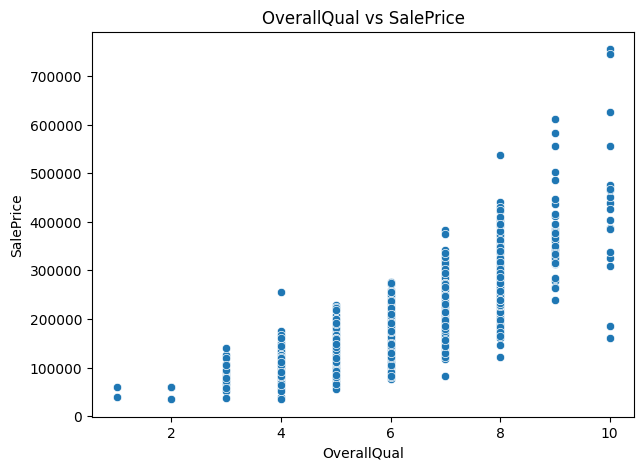

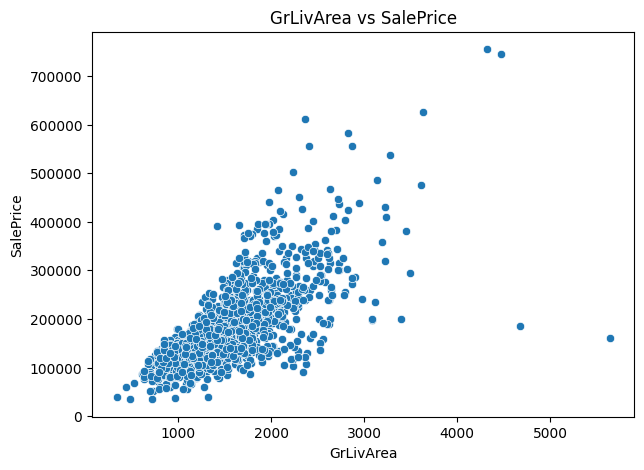

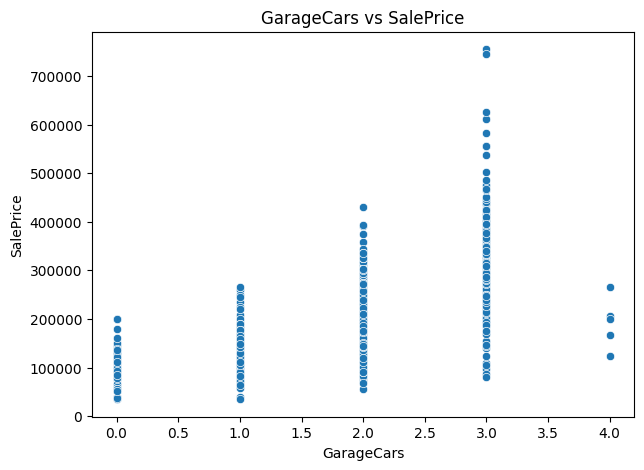

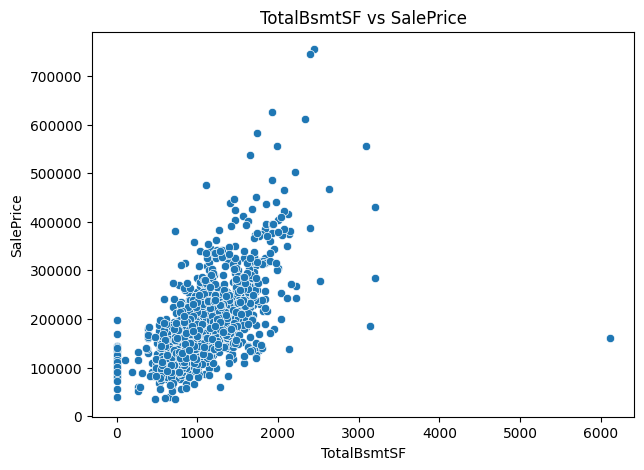

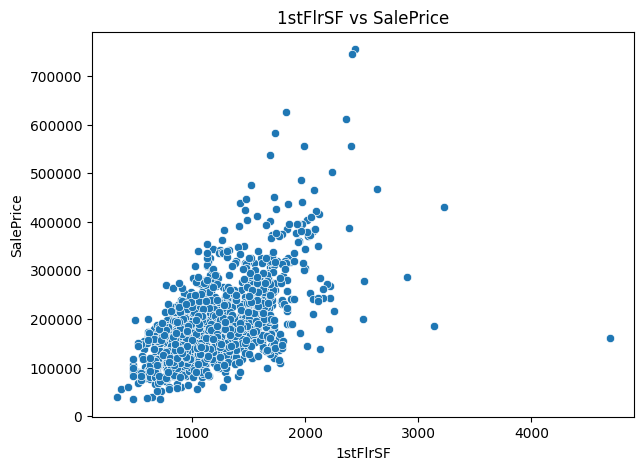

In [16]:
important_features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "1stFlrSF"
]

for feature in important_features:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=feature,
        y="SalePrice"
    )

    plt.title(f"{feature} vs SalePrice")
    plt.show()

## Step 13: Outlier Analysis

I use boxplots to inspect important numerical variables for potential
outliers.

Outliers are not automatically removed because extreme values can
sometimes represent genuine houses rather than incorrect records.

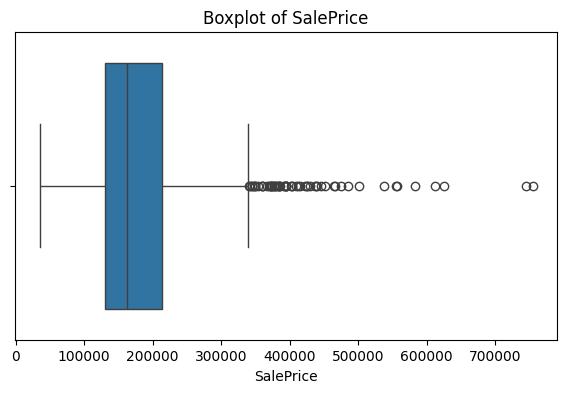

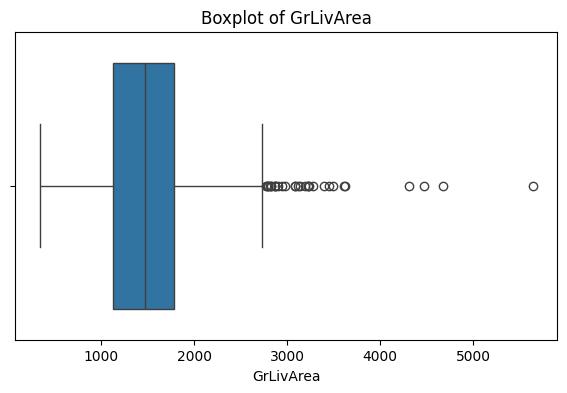

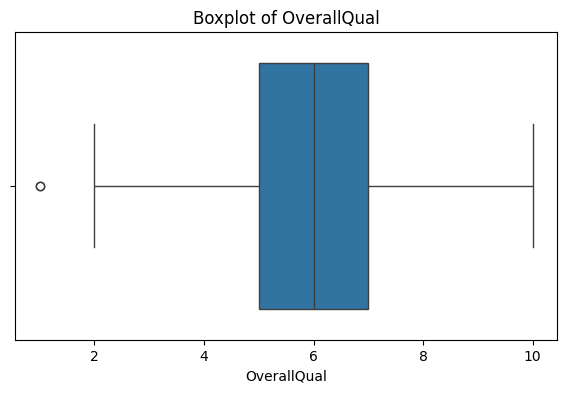

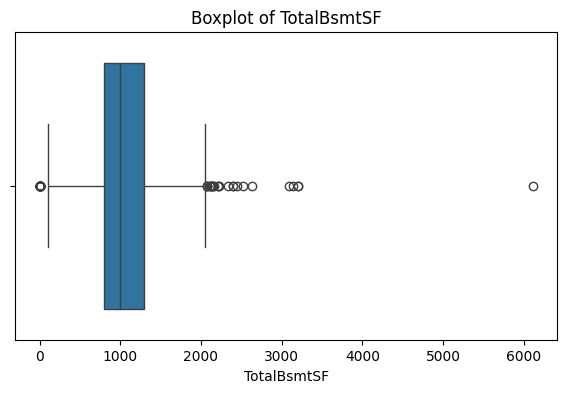

In [17]:
outlier_features = [
    "SalePrice",
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF"
]

for feature in outlier_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[feature])

    plt.title(f"Boxplot of {feature}")
    plt.show()

"I investigated the outliers, but I did not automatically remove them because an extreme house price or large house area can be a genuine observation."

## Step 14: Separate Features and Target

I separate the input variables from the target variable.

`X` contains the house characteristics used for prediction, while `y`
contains `SalePrice`, which is the value that the model must predict.

In [18]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 80)
Target shape: (1460,)


X → input features

y → target variable

## Step 15: Remove the ID Column

The `Id` column is an identifier and does not represent a meaningful
characteristic of the house.

Therefore, I remove it before training the models.

In [19]:
if "Id" in X.columns:
    X = X.drop("Id", axis=1)

print("Features after removing Id:", X.shape)

Features after removing Id: (1460, 79)


## Step 16: Train-Test Split

I divide the dataset into training and testing data.

The training data is used to train the machine-learning models, while the
testing data is kept unseen during training and used to evaluate how well
the models generalize to new observations.

I use an 80:20 split.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1168
Testing samples: 292


## Step 17: Identify Numerical and Categorical Features

I identify numerical and categorical features from the training dataset.

The preprocessing applied to each type of feature will be different.

In [21]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 36
Categorical features: 43


## Step 18: Data Preprocessing

I create separate preprocessing pipelines for numerical and categorical
features.

For numerical features, missing values are replaced with the median and
the values are standardized.

For categorical features, missing values are replaced with the most
frequent category and categorical values are converted into numerical
values using one-hot encoding.

Using a pipeline ensures that the same preprocessing is applied consistently
to training and testing data.

In [22]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created")

Preprocessing pipeline created


## Step 19: Linear Regression

I train a Linear Regression model as a baseline model.

Linear Regression is a simple regression algorithm that helps establish
a reference performance before comparing more complex algorithms.

In [23]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R2  :", linear_r2)

Linear Regression
MAE : 18288.189307726738
RMSE: 29473.84943259002
R2  : 0.8867443473836869


In [24]:

import statsmodels.api as sm

print("statsmodels imported successfully!")

statsmodels imported successfully!


In [25]:
import sys
!{sys.executable} -m pip install statsmodels

You should consider upgrading via the 'C:\Users\GEETHIKA\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [26]:
import statsmodels.api as sm

print("P-VALUE ANALYSIS")
print("=" * 60)

P-VALUE ANALYSIS


In [27]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 36
Categorical features: 43


In [28]:
pvalue_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


In [29]:
pvalue_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            )
        )
    ]
)

In [30]:
pvalue_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            pvalue_numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            pvalue_categorical_transformer,
            categorical_features
        )
    ]
)

In [31]:
X_train_pvalue = pvalue_preprocessor.fit_transform(
    X_train
)


# Convert sparse matrix to normal NumPy array
if hasattr(X_train_pvalue, "toarray"):
    X_train_pvalue = X_train_pvalue.toarray()

In [32]:
pvalue_feature_names = (
    pvalue_preprocessor.get_feature_names_out()
)


In [33]:
X_train_pvalue = sm.add_constant(
    X_train_pvalue
)


In [34]:
ols_model = sm.OLS(
    y_train,
    X_train_pvalue
).fit()


C:\Users\GEETHIKA\AppData\Local\Temp\ipykernel_14332\3810534723.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


In [35]:
print(
    ols_model.summary()
)

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.920
Method:                 Least Squares   F-statistic:                     56.84
Date:                Tue, 29 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:02:59   Log-Likelihood:                -13197.
No. Observations:                1168   AIC:                         2.687e+04
Df Residuals:                     928   BIC:                         2.809e+04
Df Model:                         239                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4.628e+05   1.01e+05     -4.588      0.0

## Step 20: Ridge Regression

I train a Ridge Regression model.

Ridge Regression is a regularized version of Linear Regression. It applies
L2 regularization to control the size of model coefficients and can help
reduce overfitting when many features are present.

In [36]:
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=10.0))
    ]
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_predictions
)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)

print("Ridge Regression")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2  :", ridge_r2)

Ridge Regression
MAE : 19040.57781947507
RMSE: 30646.493974333767
R2  : 0.8775531095354413


## Step 21: Decision Tree Regression

I train a Decision Tree Regressor.

A decision tree can model non-linear relationships between house
characteristics and sale price.

In [37]:
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=10,
                random_state=42
            )
        )
    ]
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_predictions)
)

tree_r2 = r2_score(
    y_test,
    tree_predictions
)

print("Decision Tree")
print("MAE :", tree_mae)
print("RMSE:", tree_rmse)
print("R2  :", tree_r2)

Decision Tree
MAE : 26354.807250928912
RMSE: 40596.37710142962
R2  : 0.7851374518834369


## Step 22: Random Forest Regression

I train a Random Forest Regressor.

Random Forest combines multiple decision trees and can capture complex
non-linear relationships in tabular data.

In [38]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)

Random Forest
MAE : 17360.3777283105
RMSE: 28398.152812603625
R2  : 0.8948603929762028


## Step 23: Gradient Boosting Regression

I train a Gradient Boosting Regressor.

Gradient Boosting builds models sequentially, with later models attempting
to improve the errors made by previous models.

In [39]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_model.fit(X_train, y_train)

gradient_predictions = gradient_model.predict(X_test)

gradient_mae = mean_absolute_error(
    y_test,
    gradient_predictions
)

gradient_rmse = np.sqrt(
    mean_squared_error(y_test, gradient_predictions)
)

gradient_r2 = r2_score(
    y_test,
    gradient_predictions
)

print("Gradient Boosting")
print("MAE :", gradient_mae)
print("RMSE:", gradient_rmse)
print("R2  :", gradient_r2)

Gradient Boosting
MAE : 16670.238223738208
RMSE: 27786.957486725827
R2  : 0.899337396414036


## Step 24: Model Comparison

I create a comparison table containing the MAE, RMSE, and R² values
of all the trained models.

This allows me to compare the models objectively and select the model
with the strongest validation performance.

In [40]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        ridge_mae,
        tree_mae,
        rf_mae,
        gradient_mae
    ],
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        tree_rmse,
        rf_rmse,
        gradient_rmse
    ],
    "R2": [
        linear_r2,
        ridge_r2,
        tree_r2,
        rf_r2,
        gradient_r2
    ]
})

results = results.sort_values(
    by="RMSE",
    ascending=True
)

display(results)

,Model,MAE,RMSE,R2
4,Gradient Boosting,16670.238224,27786.957487,0.899337
3,Random Forest,17360.377728,28398.152813,0.894860
0,Linear Regression,18288.189308,29473.849433,0.886744
1,Ridge Regression,19040.577819,30646.493974,0.877553
2,Decision Tree,26354.807251,40596.377101,0.785137


How to interpret it

For:

MAE → lower is better

RMSE → lower is better

R² → higher is better

Don't decide the winner before seeing your actual output.

## Step 25: Visual Comparison of Models

I create a bar chart to compare the RMSE values of the models.

This makes it easier to visually identify which models have lower
prediction errors.

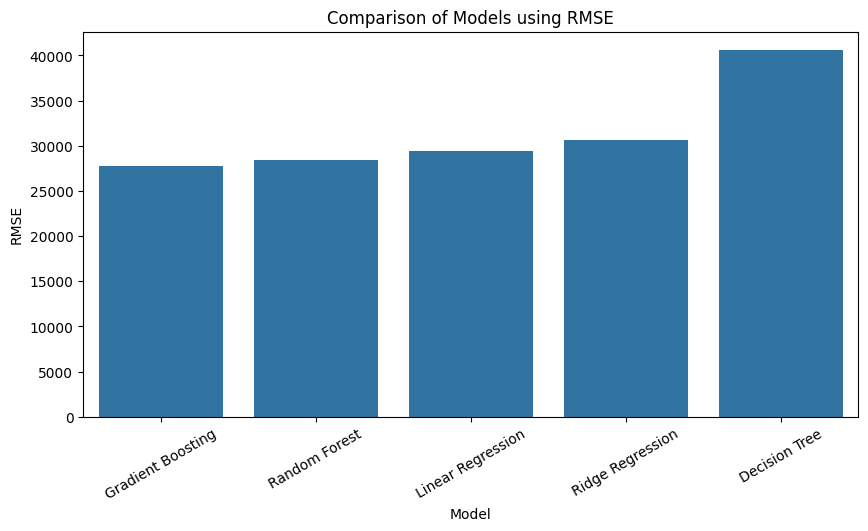

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.xticks(rotation=30)
plt.title("Comparison of Models using RMSE")
plt.ylabel("RMSE")

plt.show()

## Step 26: Cross-Validation

I use 5-fold cross-validation to obtain a more reliable estimate of
model performance.

Instead of evaluating the model on only one split, the data is divided
into five folds and the model is evaluated multiple times.

In [42]:
cv_scores = cross_val_score(
    gradient_model,
    X,
    y,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

cv_rmse = -cv_scores

print("Cross-validation RMSE:")
print(cv_rmse)

print("\nMean CV RMSE:", cv_rmse.mean())
print("Standard Deviation:", cv_rmse.std())

Cross-validation RMSE:
[22501.24294051 32528.82216449 27440.96209508 21925.57249245
 25740.14416332]

Mean CV RMSE: 26027.348771168974
Standard Deviation: 3836.872069019358


## Step 27: Compare Actual and Predicted Prices

I compare the actual house prices with the prices predicted by the
selected model.

This helps demonstrate how close the model predictions are to the
real values.

In [43]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": gradient_predictions
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,154500,146763.887449
1,325000,337840.661832
2,115000,118599.288282
3,159000,149109.915690
4,315500,336517.728802
5,75500,82378.513211
6,311500,226378.402150
7,146000,138833.771905
8,84500,82011.894024
9,135500,134349.386476


## Step 28: Actual vs Predicted Visualization

I plot actual house prices against predicted prices.

If predictions are accurate, the points should be close to the diagonal
reference line representing perfect prediction.

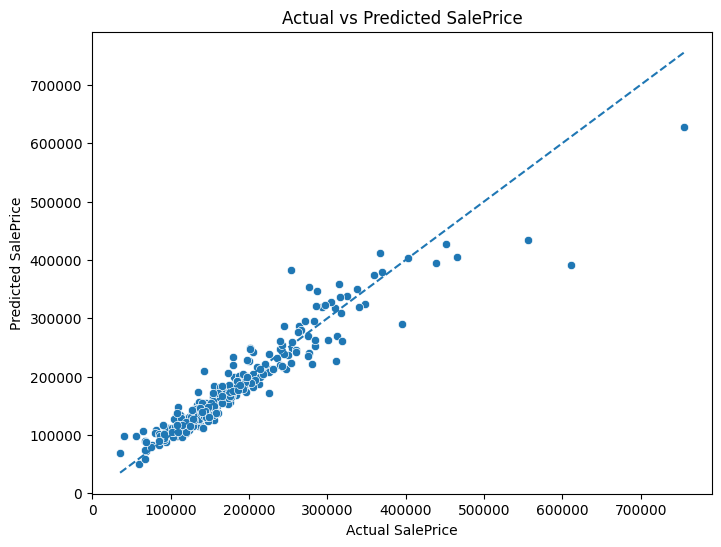

In [44]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=gradient_predictions
)

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted SalePrice")

min_value = min(
    y_test.min(),
    gradient_predictions.min()
)

max_value = max(
    y_test.max(),
    gradient_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

## Step 29: Sample Prediction on Unseen Data

I use one house from the testing dataset as an unseen example and
generate its predicted sale price.

This demonstrates how the trained model can be used to make a prediction
for a house whose actual price was not used during model training.

In [45]:
sample_house = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

predicted_price = gradient_model.predict(
    sample_house
)[0]

print("Actual Price   :", actual_price)
print("Predicted Price:", predicted_price)

Actual Price   : 154500
Predicted Price: 146763.88744920547


LINEAR REGRESSION : R² vs P-VALUE
R²       : 0.8867443473836869
P-value  : 0.0

Scenario: BEST SCENARIO
High R² + Low P-value
Model explains the target well
and is statistically significant.


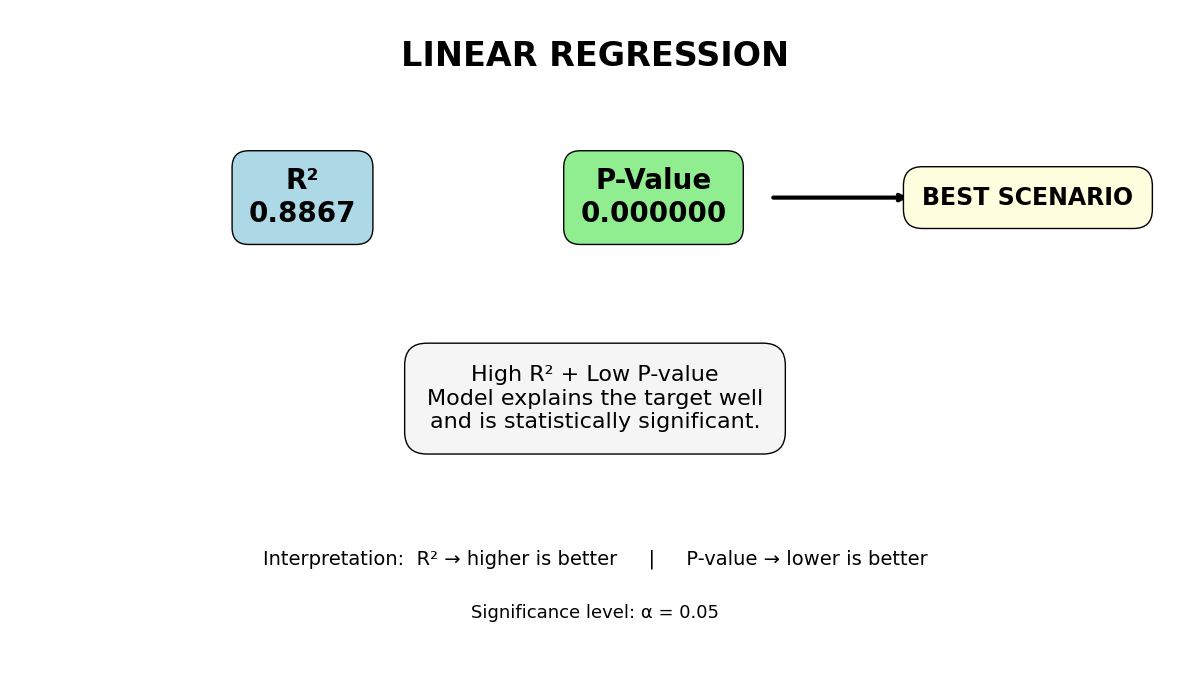

In [46]:


import matplotlib.pyplot as plt


r2_value = linear_r2


p_value = ols_model.f_pvalue

print("=" * 60)
print("LINEAR REGRESSION : R² vs P-VALUE")
print("=" * 60)

print("R²       :", r2_value)
print("P-value  :", p_value)



if r2_value >= 0.70 and p_value < 0.05:

    scenario = "BEST SCENARIO"
    explanation = (
        "High R² + Low P-value\n"
        "Model explains the target well\n"
        "and is statistically significant."
    )

elif r2_value < 0.70 and p_value < 0.05:

    scenario = "BETTER THAN NOT HAVING A MODEL"
    explanation = (
        "Low R² + Low P-value\n"
        "Model is statistically significant,\n"
        "but explanatory power is limited."
    )

elif r2_value >= 0.70 and p_value >= 0.05:

    scenario = "MODEL MAY BE UNRELIABLE"
    explanation = (
        "High R² + High P-value\n"
        "Good apparent fit, but statistical\n"
        "evidence is weak."
    )

else:

    scenario = "WORST SCENARIO"
    explanation = (
        "Low R² + High P-value\n"
        "Poor explanatory power and\n"
        "weak statistical evidence."
    )

print("\nScenario:", scenario)
print(explanation)




fig, ax = plt.subplots(figsize=(12, 7))

# Hide axes
ax.axis("off")

# Title
ax.text(
    0.5,
    0.93,
    "LINEAR REGRESSION",
    ha="center",
    va="center",
    fontsize=24,
    fontweight="bold"
)

# R² box
ax.text(
    0.25,
    0.72,
    f"R²\n{r2_value:.4f}",
    ha="center",
    va="center",
    fontsize=20,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightblue",
        edgecolor="black"
    )
)

# P-value box
ax.text(
    0.55,
    0.72,
    f"P-Value\n{p_value:.6f}",
    ha="center",
    va="center",
    fontsize=20,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightgreen",
        edgecolor="black"
    )
)

# Arrow
ax.annotate(
    "",
    xy=(0.77, 0.72),
    xytext=(0.65, 0.72),
    arrowprops=dict(
        arrowstyle="->",
        lw=3
    )
)

# Scenario box
ax.text(
    0.87,
    0.72,
    scenario,
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="lightyellow",
        edgecolor="black"
    )
)

# Explanation
ax.text(
    0.5,
    0.42,
    explanation,
    ha="center",
    va="center",
    fontsize=16,
    bbox=dict(
        boxstyle="round,pad=1",
        facecolor="whitesmoke",
        edgecolor="black"
    )
)

# Threshold information
ax.text(
    0.5,
    0.18,
    "Interpretation:  R² → higher is better     |     P-value → lower is better",
    ha="center",
    va="center",
    fontsize=14
)

ax.text(
    0.5,
    0.10,
    "Significance level: α = 0.05",
    ha="center",
    va="center",
    fontsize=13
)

plt.tight_layout()
plt.show()

Lab - 3

In [64]:

import os
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [61]:
os.makedirs("results", exist_ok=True)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [62]:
trained_models = {}
baseline_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    baseline_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

In [63]:
baseline_df = pd.DataFrame(baseline_results)
baseline_df = baseline_df.sort_values("RMSE")

display(baseline_df.round(4))

baseline_df.to_csv(
    "results/lab3_baseline_results.csv",
    index=False
)

print("Lab 3 completed successfully!")

,Model,MAE,RMSE,R2
4,Gradient Boosting,16670.2382,27786.9575,0.8993
3,Random Forest,17360.3777,28398.1528,0.8949
0,Linear Regression,18288.1893,29473.8494,0.8867
1,Ridge Regression,19040.5778,30646.4940,0.8776
2,Decision Tree,26354.8073,40596.3771,0.7851


Lab 3 completed successfully!


Lab - 4

In [67]:

from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
experiment_results = []

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_test)

    experiment_results.append({
        "Experiment_Time": datetime.now().isoformat(),
        "Model": name,
        "Parameters": str(
            pipeline.named_steps["model"].get_params()
        ),
        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions),
        "Dataset": "House Prices",
        "Training_Rows": len(X_train),
        "Testing_Rows": len(X_test)
    })

,Experiment_Time,Model,Parameters,MAE,RMSE,R2,Dataset,Training_Rows,Testing_Rows
0,2026-09-29T22:54:55.419961,Linear Regression,"{'copy_X': True, 'fit_intercept': True, 'n_job...",18288.1893,29473.8494,0.8867,House Prices,1168,292
1,2026-09-29T22:54:55.451844,Ridge Regression,"{'alpha': 10.0, 'copy_X': True, 'fit_intercept...",19040.5778,30646.4940,0.8776,House Prices,1168,292
2,2026-09-29T22:54:55.475671,Decision Tree,"{'ccp_alpha': 0.0, 'criterion': 'squared_error...",26354.8073,40596.3771,0.7851,House Prices,1168,292
3,2026-09-29T22:54:55.656176,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri...",17360.3777,28398.1528,0.8949,House Prices,1168,292
4,2026-09-29T22:54:55.687264,Gradient Boosting,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ...",16670.2382,27786.9575,0.8993,House Prices,1168,292


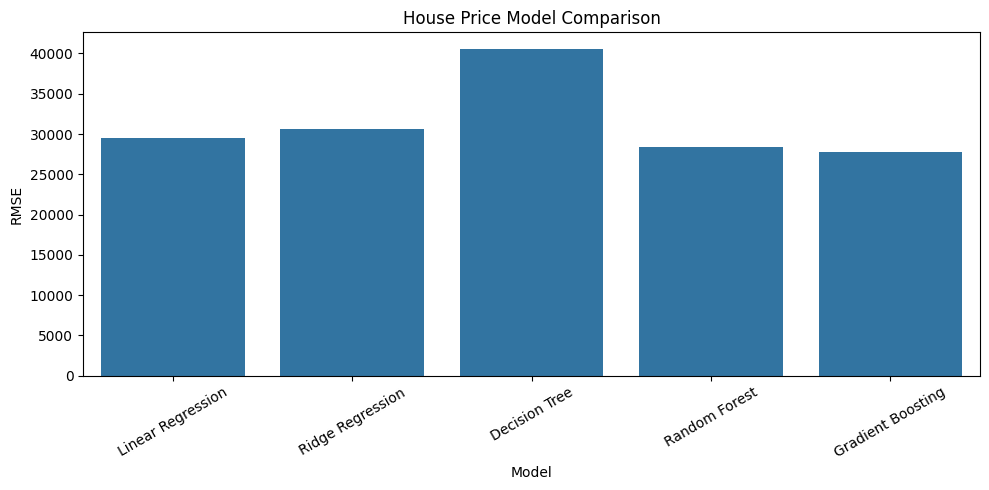

Lab 4 completed successfully!


In [66]:
tracking_df = pd.DataFrame(experiment_results)

display(tracking_df.round(4))

tracking_df.to_csv(
    "results/lab4_experiment_tracking.csv",
    index=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tracking_df,
    x="Model",
    y="RMSE"
)

plt.title("House Price Model Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Lab 4 completed successfully!")

Lab - 5

In [57]:

# LAB 5 - DATA VALIDATION

print("=" * 60)
print("LAB 5 - HOUSE PRICE DATA VALIDATION")
print("=" * 60)



LAB 5 - HOUSE PRICE DATA VALIDATION


In [58]:
# Check dataset
assert len(df) > 0, "Dataset is empty"

# Check target
assert "SalePrice" in df.columns

# Check target values
assert df["SalePrice"].notna().all()
assert (df["SalePrice"] > 0).all()

# Check duplicates
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

# Check missing values
missing_data = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().sum().values / len(df) * 100
    ).round(2)
})

display(missing_data)

Duplicate rows: 0


,Column,Missing_Count,Missing_Percentage
0,Id,0,0.00
1,MSSubClass,0,0.00
2,MSZoning,0,0.00
3,LotFrontage,259,17.74
4,LotArea,0,0.00
...,...,...,...
76,MoSold,0,0.00
77,YrSold,0,0.00
78,SaleType,0,0.00
79,SaleCondition,0,0.00


In [59]:
# Validate training and testing data
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

print("Dataset validation passed!")

# Select the model with lowest baseline RMSE
best_model_name = baseline_df.iloc[0]["Model"]
final_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)

Dataset validation passed!
Selected Model: Gradient Boosting


In [60]:
# Generate predictions
test_predictions = final_model.predict(X_test)

# Validate predictions
assert len(test_predictions) == len(X_test)
assert np.isfinite(test_predictions).all()

print("Prediction validation passed!")

# Save prediction results
prediction_df = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": test_predictions
})

display(prediction_df.head(10))

prediction_df.to_csv(
    "results/lab5_house_predictions.csv",
    index=False
)

print("Lab 5 completed successfully!")

Prediction validation passed!


,Actual_Price,Predicted_Price
0,154500,146763.887449
1,325000,337840.661832
2,115000,118599.288282
3,159000,149109.915690
4,315500,336517.728802
5,75500,82378.513211
6,311500,226378.402150
7,146000,138833.771905
8,84500,82011.894024
9,135500,134349.386476


Lab 5 completed successfully!


Lab - 6

In [72]:

import os
import json
import joblib
from datetime import datetime

In [68]:
registry_dir = "results/model_registry"

os.makedirs(registry_dir, exist_ok=True)

# Evaluate selected model
registry_predictions = final_model.predict(X_test)

registry_mae = mean_absolute_error(
    y_test, registry_predictions
)

registry_rmse = np.sqrt(
    mean_squared_error(y_test, registry_predictions)
)

registry_r2 = r2_score(
    y_test, registry_predictions
)

In [69]:
# Create registry metadata
model_registry = {
    "model_name": "House Price Prediction",
    "model_type": best_model_name,
    "version": "1.0",
    "dataset": "House Prices",
    "target": "SalePrice",
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "created_at": datetime.now().isoformat(),
    "MAE": float(registry_mae),
    "RMSE": float(registry_rmse),
    "R2": float(registry_r2),
    "status": "registered"
}

In [70]:
# Save metadata
metadata_path = (
    f"{registry_dir}/house_price_model_v1.json"
)

with open(metadata_path, "w") as file:
    json.dump(model_registry, file, indent=4)

print("Model metadata saved!")

# Save complete preprocessing + model pipeline
model_path = (
    f"{registry_dir}/house_price_model_v1.pkl"
)

joblib.dump(final_model, model_path)

print("Model registered successfully!")

# Reload registered model
registered_model = joblib.load(model_path)

# Test reloaded model
loaded_predictions = registered_model.predict(X_test)

assert np.allclose(
    registry_predictions,
    loaded_predictions
)

Model metadata saved!
Model registered successfully!


In [71]:
print("Registered model validation passed!")

# Create registry report
registry_report = pd.DataFrame([model_registry])

display(registry_report)

registry_report.to_csv(
    f"{registry_dir}/house_price_registry_report.csv",
    index=False
)

print("Lab 6 completed successfully!")

Registered model validation passed!


,model_name,model_type,version,dataset,target,training_rows,testing_rows,created_at,MAE,RMSE,R2,status
0,House Price Prediction,Gradient Boosting,1.0,House Prices,SalePrice,1168,292,2026-09-29T22:56:38.735493,16670.238224,27786.957487,0.899337,registered


Lab 6 completed successfully!
